In [1]:
import sys

sys.path.append("..")
import cupynumeric as np
from src.mixed_fps.simulate_quantization import FMT
from src.qm.hamsim import simulate_hamiltonian

[0 - 1fb7f9f00]    0.000000 {5}{module_config}: Module numa can not detect resources.


In [2]:
# formats = NATIVE | FMT
# formats.pop("fp64")
# formats.pop("fp32")

formats = FMT
formats.pop("bf16_e8m7")
formats.pop("fp16_e5m10")
formats = formats | {"fp16": np.float16}

formats

{'fp8_e4m3': {'exp_bits': 4, 'man_bits': 3, 'bias': 7},
 'fp8_e5m2': {'exp_bits': 5, 'man_bits': 2, 'bias': 15},
 'fp8_e3m4': {'exp_bits': 3, 'man_bits': 4, 'bias': 3},
 'fp8_e2m5': {'exp_bits': 2, 'man_bits': 5, 'bias': 1},
 'fp10_e5m4': {'exp_bits': 5, 'man_bits': 4, 'bias': 15},
 'fp12_e5m6': {'exp_bits': 5, 'man_bits': 6, 'bias': 15},
 'bf10_e8m1': {'exp_bits': 8, 'man_bits': 1, 'bias': 127},
 'bf12_e8m3': {'exp_bits': 8, 'man_bits': 3, 'bias': 127},
 'fp16': numpy.float16}

In [15]:
n = 100
# generate random Hermitian components H1 and H2
A = np.random.randn(n, n) + 1j * np.random.randn(n, n)
B = np.random.randn(n, n) + 1j * np.random.randn(n, n)
H1 = (A + A.conj().T) / 2
H2 = (B + B.conj().T) / 2
H_terms = [H1, H2]

In [16]:
errs_r = {}

for r in [25, 50, 100]:
    t = 0.1

    # initial state |ψ₀⟩ random normalized vector
    psi = np.random.randn(n) + 1j * np.random.randn(n)
    psi /= np.linalg.norm(psi)
    psi_exact = np.linalg.expm(-1j * (H1 + H2) * t).dot(psi)

    errs = {}
    for fmt in formats:
        print(f"{fmt}")
        fmts = [fmt]
        # fmts = ["fp16"]
        # Rotate through mixed precisions: tiny + native
        # fmts = ["fp4_e2m1", "fp8_e4m3", "fp64", "fp8_e5m2"]
        # fmts = ["fp64"] * len(H_terms)  # all native fp64 for reference

        # psi_final, meta = simulate_hamiltonian(H_terms, psi, t, r, fmts, verbose=False, normalize=True)
        psi_final, meta = simulate_hamiltonian(
            H_terms,
            psi,
            t,
            r,
            fmt_list=fmts,  # native 64-bit
            compute_dtype=np.float32,  # feed 64-bit into solver
            work_dtype=np.float32,  # eigensolver in 64-bit
            out_dtype=np.complex64,  # output complex 64-bit
            verbose=False,
        )
        # normalize final state
        psi_final /= np.linalg.norm(psi_final)

        err = np.linalg.norm(psi_exact - psi_final)
        errs[fmt] = err

    errs_r[r] = errs

fp8_e4m3
fp8_e5m2
fp8_e3m4
fp8_e2m5
fp10_e5m4
fp12_e5m6
bf10_e8m1
bf12_e8m3
fp16
fp8_e4m3
fp8_e5m2
fp8_e3m4
fp8_e2m5
fp10_e5m4
fp12_e5m6
bf10_e8m1
bf12_e8m3
fp16
fp8_e4m3
fp8_e5m2
fp8_e3m4
fp8_e2m5
fp10_e5m4
fp12_e5m6
bf10_e8m1
bf12_e8m3
fp16


In [17]:
# mantissa_memory = {
#     "fp8_e4m3": 0.375,
#     "fp8_e5m2": 0.25,
#     "fp8_e3m4": 0.5,
#     "fp8_e2m5": 0.625,
#     "fp16": 1.25,
#     "fp32": 2.875,
#     "fp64": 6.5,
# }

mantissa_memory = {
    # FP8 family
    "fp8_e4m3": 0.375,
    "fp8_e5m2": 0.25,
    "fp8_e3m4": 0.5,
    "fp8_e2m5": 0.625,
    # Intermediate formats
    "fp10_e5m4": 0.5,
    "fp12_e5m6": 0.75,
    "bf10_e8m1": 0.125,
    "bf12_e8m3": 0.375,
    # FP16 and bfloat16
    "fp16_e5m10": 1.25,
    "bf16_e8m7": 0.875,
    # Higher precision reference
    "fp16": 1.25,
    "fp32": 2.875,
    "fp64": 6.5,
}

r=25
r=50
r=100


Text(0, 0.5, 'Trotter error')

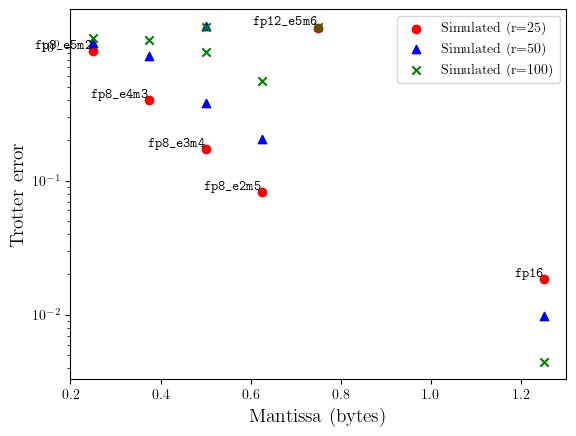

In [18]:
import matplotlib.pyplot as plt

# use latex
plt.rc("text", usetex=True)
plt.rc("font", family="serif")

markers = ["o", "^", "x", "s", "D", "*", "P", "v", "<", ">"]
colors = [
    "red",
    "blue",
    "green",
    "orange",
    "purple",
    "brown",
    "pink",
    "gray",
    "olive",
    "cyan",
]
for r in errs_r:
    print(f"r={r}")

    plt.scatter(
        [mantissa_memory[fmt] for fmt in errs_r[r].keys()],
        [errs_r[r][fmt] for fmt in errs_r[r].keys()],
        label=f"Simulated (r={r})",
        marker=markers.pop(0),
        c=colors.pop(0),
        # c="red",
    )

r_min = min(errs_r.keys())
for fmt in errs_r[r_min].keys():
    plt.text(
        mantissa_memory[fmt],
        errs_r[r_min][fmt],
        f"$\\texttt{{{fmt}}}$",
        fontsize=10,
        ha="right",
        va="bottom",
    )
    # plt.text(mantissa_memory[fmt], errs2[fmt], f"$\\texttt{{{fmt}}}$", fontsize=10, ha='left', va='bottom')

plt.legend()
plt.yscale("log")
plt.xlabel("Mantissa (bytes)", fontsize=14)
plt.ylabel("Trotter error", fontsize=14)

In [14]:
errs_r

{25: {'fp8_e4m3': array(0.48083737),
  'fp8_e5m2': array(0.81609361),
  'fp8_e3m4': array(0.15436849),
  'fp8_e2m5': array(0.08792405),
  'fp10_e5m4': array(inf),
  'fp12_e5m6': array(1.34637907),
  'bf10_e8m1': array(nan),
  'bf12_e8m3': array(inf),
  'fp16': array(0.0179014)},
 50: {'fp8_e4m3': array(0.97925869),
  'fp8_e5m2': array(1.11876059),
  'fp8_e3m4': array(0.42932447),
  'fp8_e2m5': array(0.25894096),
  'fp10_e5m4': array(1.46079481),
  'fp12_e5m6': array(inf),
  'bf10_e8m1': array(inf),
  'bf12_e8m3': array(inf),
  'fp16': array(0.01014397)},
 100: {'fp8_e4m3': array(1.14290974),
  'fp8_e5m2': array(1.18227044),
  'fp8_e3m4': array(0.92015449),
  'fp8_e2m5': array(0.52695323),
  'fp10_e5m4': array(1.39985396),
  'fp12_e5m6': array(1.39985383),
  'bf10_e8m1': array(nan),
  'bf12_e8m3': array(inf),
  'fp16': array(0.00475424)}}

In [13]:
np.linalg.norm(psi_final)

array(1., dtype=float32)

In [14]:
n = 10
# generate random Hermitian components H1 and H2
A = np.random.randn(n, n) + 1j * np.random.randn(n, n)
B = np.random.randn(n, n) + 1j * np.random.randn(n, n)
H1 = (A + A.conj().T) / 2
H2 = (B + B.conj().T) / 2
H_terms = [H1, H2]

psi = np.random.randn(n) + 1j * np.random.randn(n)
psi /= np.linalg.norm(psi)

In [15]:
import cupynumeric as np

...

t = 0.4
r = 6

fmts = ["fp16", "fp32", "fp8_e4m3"]

psi_final = simulate_hamiltonian(H_terms, psi, t, r, fmts, verbose=True, normalize=True)
psi_exact = np.linalg.expm(-1j * (H1 + H2) * t).dot(psi)
print("Approx error:", np.linalg.norm(psi_exact - psi_final))

Step 0, format start: fp16
Step 1, format start: fp32
Step 2, format start: fp8_e4m3
Step 3, format start: fp16
Step 4, format start: fp32
Step 5, format start: fp8_e4m3


ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (2,) + inhomogeneous part.